Plant Disease Prediction

In [68]:
### conda activate tf210

In [69]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns



Data Preprocessing

training image preprocessing

In [29]:
training_set = tf.keras.utils.image_dataset_from_directory(
    'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 70295 files belonging to 38 classes.


In [30]:
# Display the images and their labels
for x, y in training_set:
    print(x, x.shape)  # Print image tensor and its shape
    print(y, y.shape)  # Print label tensor and its shape
    break              # Stop after the first batch

tf.Tensor(
[[[[154.75 141.75 148.75]
   [147.   134.   141.  ]
   [148.5  135.5  142.5 ]
   ...
   [156.   143.   152.  ]
   [155.   142.   151.  ]
   [155.25 142.25 151.25]]

  [[158.25 145.25 152.25]
   [163.25 150.25 157.25]
   [163.75 150.75 157.75]
   ...
   [155.5  142.5  151.5 ]
   [153.75 140.75 149.75]
   [154.   141.   150.  ]]

  [[157.   144.   151.  ]
   [180.75 167.75 174.75]
   [158.   145.   152.  ]
   ...
   [154.75 141.75 150.75]
   [154.75 141.75 150.75]
   [156.25 143.25 152.25]]

  ...

  [[197.5  183.25 190.25]
   [158.75 143.75 150.75]
   [155.75 140.75 147.75]
   ...
   [167.75 154.75 161.75]
   [164.5  151.5  158.5 ]
   [159.75 146.75 153.75]]

  [[156.25 143.25 150.25]
   [163.   150.   157.  ]
   [178.5  165.5  172.5 ]
   ...
   [168.25 155.25 162.25]
   [169.5  156.5  163.5 ]
   [165.5  152.5  159.5 ]]

  [[167.75 154.75 161.75]
   [188.   175.   182.  ]
   [193.5  180.5  187.5 ]
   ...
   [165.   152.   159.  ]
   [167.5  154.5  161.5 ]
   [166.25 153.25 16

### validaion image preprocessing

In [31]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 17572 files belonging to 38 classes.


### To avoid overshooting loss function
1.choose small learning rate default 0.001 here we have taken 0.0001
2.There may be chance of underfitting so increse number of neuron 
3.Add more convoloutional layer to extract more features from image there may 
be possibility that model unabale to capture relevant features or model is confusing
due to  loack of features so feed with more feature

### Building model

In [32]:
from tensorflow.keras.layers import Dense, Conv2D,MaxPool2D , Dropout, Flatten
from tensorflow.keras.models import Sequential

In [33]:
model=Sequential()

building convolution layer

In [34]:
model.add(Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=32,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [35]:
model.add(Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=64,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [36]:
model.add(Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=128,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [37]:
model.add(Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=256,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [38]:
model.add(Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=512,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))


In [39]:
model.add(Dropout(0.25))

In [40]:
model.add(Flatten())

In [41]:
model.add(Dense(units=1500,activation='relu'))

In [42]:
model.add(Dropout(0.4)) #To avoid overfitting

In [43]:
#Output Layer
model.add(Dense(units=38,activation='softmax'))

### comiling and Training phase

In [44]:
model.compile(optimizer=tf.keras.optimizers.legacy.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [45]:
model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_10 (Conv2D)          (None, 128, 128, 32)      896       
                                                                 
 conv2d_11 (Conv2D)          (None, 126, 126, 32)      9248      
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 63, 63, 32)       0         
 2D)                                                             
                                                                 
 conv2d_12 (Conv2D)          (None, 63, 63, 64)        18496     
                                                                 
 conv2d_13 (Conv2D)          (None, 61, 61, 64)        36928     
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 30, 30, 64)       0         
 2D)                                                  

In [46]:
training_history = model.fit(x=training_set,validation_data=validation_set,epochs=10)

Epoch 1/10
2197/2197 [==============================] - 230s 104ms/step - loss: 1.3435 - accuracy: 0.6063 - val_loss: 0.5037 - val_accuracy: 0.8399
Epoch 2/10
2197/2197 [==============================] - 227s 103ms/step - loss: 0.4437 - accuracy: 0.8599 - val_loss: 0.2833 - val_accuracy: 0.9067
Epoch 3/10
2197/2197 [==============================] - 228s 104ms/step - loss: 0.2674 - accuracy: 0.9135 - val_loss: 0.2034 - val_accuracy: 0.9354
Epoch 4/10
2197/2197 [==============================] - 227s 103ms/step - loss: 0.1854 - accuracy: 0.9398 - val_loss: 0.1518 - val_accuracy: 0.9515
Epoch 5/10
2197/2197 [==============================] - 229s 104ms/step - loss: 0.1409 - accuracy: 0.9544 - val_loss: 0.2041 - val_accuracy: 0.9340
Epoch 6/10
2197/2197 [==============================] - 226s 103ms/step - loss: 0.1099 - accuracy: 0.9637 - val_loss: 0.1991 - val_accuracy: 0.9396
Epoch 7/10
2197/2197 [==============================] - 231s 105ms/step - loss: 0.0924 - accuracy: 0.9699 - val_

### Evaluating Model

In [47]:
#Training set Accuracy
train_loss, train_acc = model.evaluate(training_set)
print(train_loss, train_acc)

2197/2197 [==============================] - 83s 38ms/step - loss: 0.0502 - accuracy: 0.9838
0.05016058683395386 0.9837968349456787


In [48]:
#Validation set Accuracy
val_loss, val_acc = model.evaluate(validation_set)
print(val_loss, val_acc)

550/550 [==============================] - 21s 37ms/step - loss: 0.1667 - accuracy: 0.9517
0.16673627495765686 0.9516844749450684


### saving model

In [ ]:
model.save('trained_model.keras')

In [ ]:
#Recording History in json
import json
with open('training_hist.json','w') as f:
  json.dump(training_history.history,f)

In [ ]:
print(training_history.history.keys())

### Accuracy Visualization

In [ ]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='red',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='blue',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()

### Some other metrics for model evoluation

In [ ]:
class_name = validation_set.class_names
class_name

In [ ]:
test_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=1,
    image_size=(128, 128),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

In [55]:
# Predict probabilities for the test images
y_pred = model.predict(test_set)

# Get the predicted class for each image
predicted_categories = tf.argmax(y_pred, axis=1)

17572/17572 [==============================] - 107s 6ms/step


In [56]:
# Combine the true labels from all test batches
true_categories = tf.concat(
    [y for x, y in test_set],
    axis=0
)

In [57]:
# Convert true one-hot labels to class indices
Y_true = tf.argmax(true_categories, axis=1)
# Display the true labels
print(Y_true)

tf.Tensor([ 0  0  0 ... 37 37 37], shape=(17572,), dtype=int64)


In [58]:
predicted_categories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [60]:
from sklearn.metrics import confusion_matrix,classification_report
cm = confusion_matrix(Y_true,predicted_categories)

In [61]:
# Precision Recall Fscore
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.80      0.89       504
                                 Apple___Black_rot       0.98      0.98      0.98       497
                          Apple___Cedar_apple_rust       0.92      0.99      0.95       440
                                   Apple___healthy       0.91      0.95      0.93       502
                               Blueberry___healthy       0.96      0.94      0.95       454
          Cherry_(including_sour)___Powdery_mildew       0.99      0.96      0.97       421
                 Cherry_(including_sour)___healthy       0.99      0.97      0.98       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.91      0.93      0.92       410
                       Corn_(maize)___Common_rust_       0.99      0.99      0.99       477
               Corn_(maize)___Northern_Leaf_Blight       0.94      0.95      0.

### consusion matrix visualization

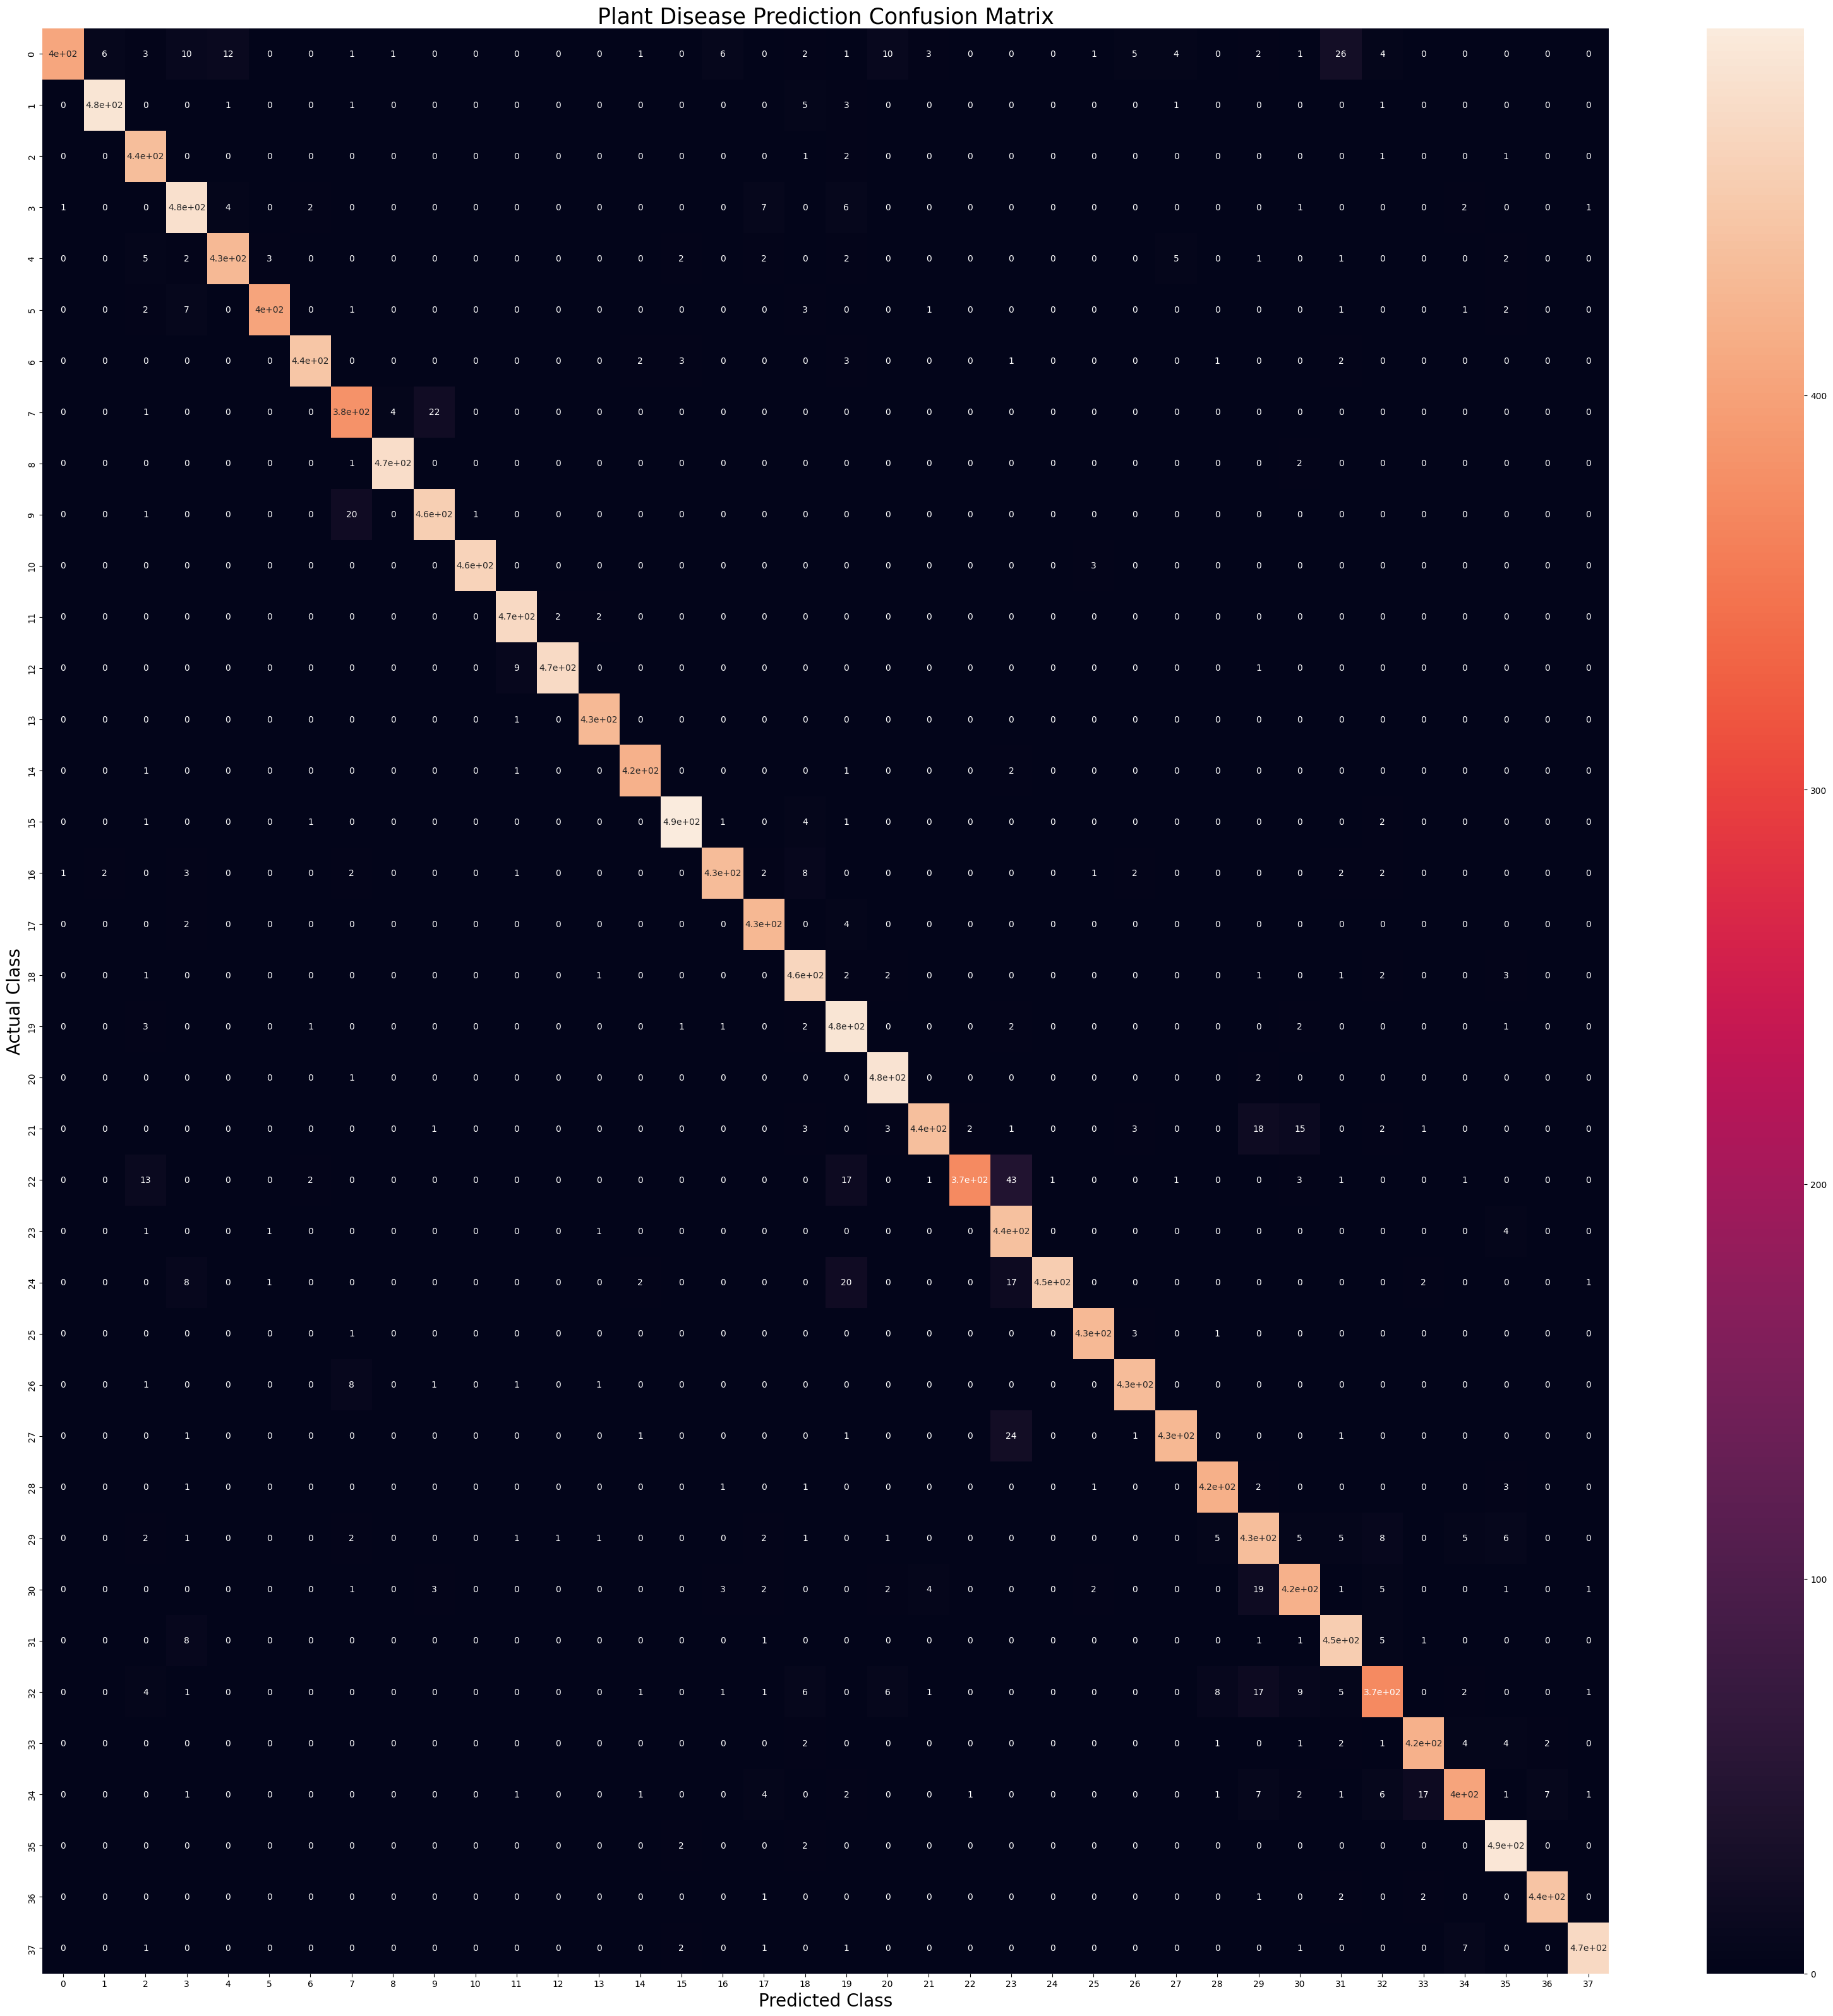

In [67]:
plt.figure(figsize=(40, 40))
sns.heatmap(cm,annot=True,annot_kws={"size": 10})

plt.xlabel('Predicted Class',fontsize = 20)
plt.ylabel('Actual Class',fontsize = 20)
plt.title('Plant Disease Prediction Confusion Matrix',fontsize = 25)
plt.show()